# CivicAI - 04 Stacking meta-classifier

This notebook builds the **final model**: a stacking classifier that combines the three models selected in Phase 5b (XGBoost, Bernoulli Naive Bayes, Random Forest), compares it with each of them on the validation split, scores the **test split once**, and saves the files the API needs.

1. What a stacking classifier is, and how this one is built
2. Choosing the settings of the final estimator
3. Fitting the final model
4. Validation comparison: the stack against its base models and the baselines
5. What the stack learned: its weights
6. Charts
7. Saving the fitted model *(the test section follows after the validation results are committed)*

**Rules followed here**

- **The decision to deploy the stack was made before any result.** It is a course requirement. The validation results below decide only the *settings* of the stack, never *whether* it is deployed. If the stack turns out to be no better than XGBoost alone, that is reported plainly, and the stack is still the deployed model.
- Everything is fitted on the **training split only**. The model is not refitted on train + validation, so the saved file matches the reported scores.
- The **test split is not opened** in sections 1-7. It is read exactly once, in a later section, after these results are saved and committed.

In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve

sys.path.insert(0, "..")                 # so that "src" can be imported from the notebooks folder
from src import features as ft
from src import train as tr

FIG_DIR = Path("../reports/figures")
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
})
SHORT = {"xgboost": "XGBoost", "naive_bayes": "Bernoulli Naive Bayes", "random_forest": "Random Forest"}

def plot_confusion(ax, row, title):
    counts = np.array([[row["actual0_pred0"], row["actual0_pred1"]], [row["actual1_pred0"], row["actual1_pred1"]]], dtype=float)
    shares = counts / counts.sum(axis=1, keepdims=True)
    ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(counts[i, j]):,}\n{shares[i, j]:.1%}", ha="center", va="center", fontsize=10,
                    color="white" if shares[i, j] > 0.55 else "black")
    ax.set_xticks([0, 1], ["Pred. 0", "Pred. 1"])
    ax.set_yticks([0, 1], ["Actual 0", "Actual 1"])
    ax.set_title(f"{title}\nmacro F1 {row['macro_f1']:.3f}, recall of class 0 {row['recall_0']:.1%}", loc="left", fontsize=9.5)
    ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)

X_train, y_train = tr.load_xy("train", "../data/processed")
X_val, y_val = tr.load_xy("val", "../data/processed")        # test.parquet is not read in this part
best_settings = json.loads(Path("../reports/best_settings.json").read_text())

print(f"Training split  : {len(X_train):,} rows, class 0 share {1 - y_train.mean():.1%}")
print(f"Validation split: {len(X_val):,} rows, class 0 share {1 - y_val.mean():.1%}")
print("Base models and their tuned settings (from reports/best_settings.json, not tuned again):")
for key, name in tr.STACK_MODELS.items():
    print(f"  {name}: {best_settings[name]}")

Training split  : 139,206 rows, class 0 share 17.2%
Validation split: 29,830 rows, class 0 share 16.8%
Base models and their tuned settings (from reports/best_settings.json, not tuned again):
  XGBoost: {'n_estimators': 600, 'learning_rate': 0.05, 'max_depth': 8, 'scale_pos_weight': 0.4556}
  Bernoulli Naive Bayes: {'alpha': 0.1, 'class_prior': None}
  Random Forest: {'n_estimators': 150, 'max_depth': 40, 'min_samples_leaf': 5}


## 1. What a stacking classifier is, and how this one is built

**The idea.** Three different models each look at a request and give a probability that it will be resolved within 7 days. A small fourth model, the **final estimator** (here a Logistic Regression), takes those three probabilities as its inputs and learns how much to trust each one. It outputs the final probability.

```
raw request fields
      |
 [clean]   RequestCleaner: the same cleaning, rare-category and time-feature code as in training
      |
      +--> XGBoost            (its own encoder + model)  --> probability 1 -+
      +--> Bernoulli NB       (0/1 encoder + model)      --> probability 2 -+--> [Logistic Regression] --> final probability
      +--> Random Forest      (its own encoder + model)  --> probability 3 -+
```

The whole thing is **one scikit-learn `Pipeline`** with two steps, `clean` and `stack`. It takes the raw API fields and returns a probability, so the API needs no other code. Each base model is itself a small pipeline of its encoder and its classifier and receives the cleaned table (Naive Bayes uses the all-0/1 encoder `build_binary_encoder`; the others use the shared encoder).

**Out-of-fold predictions.** The final estimator must learn from probabilities that the base models gave for requests they had **not** been trained on. If it learned from probabilities on requests the base models had already seen, it would see them as far more reliable than they are, and over-trust the model that memorises best (the Random Forest). So `StackingClassifier` cuts the training split into 5 folds; for each fold the base models are trained on the other 4 and predict the held-out fold. Every training row then has one honest prediction from each base model, and the final estimator learns from those. After that the base models are refitted on the whole training split for use at prediction time.

**A known compromise in the folds.** Everywhere else in this project the folds respect time (`TimeSeriesSplit`). Inside a stack that is not possible: `StackingClassifier` needs an out-of-fold prediction for **every** training row, but `TimeSeriesSplit` never validates on the first block of rows. So the stack uses **5-fold stratified cross-validation with shuffling** (`StratifiedKFold`, `random_state=42`).

This is a small, known compromise and it stays **inside the training split only**: a base model predicting a training row may have seen requests from slightly later in the same period. The validation and test splits are still entirely in the future of every training row, so they remain honest. The cost is that the out-of-fold predictions may be a little more optimistic than the predictions on the future, which could make the final estimator trust the base models slightly more than it should. Section 2 measures how big that effect is.

**Final estimator.** `LogisticRegression` on the probabilities (`stack_method="predict_proba"`, `passthrough=False`, so it sees only the three probabilities and not the original features). For two classes each base model contributes one probability (that of class 1), so the final estimator has three inputs and one weight for each.

## 2. Choosing the settings of the final estimator

Two settings are tried, 6 combinations in all:

- `class_weight`: none, or `"balanced"` (mistakes on the rare class 0 count about 5 times as much),
- `C` in {0.1, 1, 10}: the strength of regularisation (smaller = simpler).

The final estimator is fitted on the **out-of-fold probabilities of the training split** and scored on the **validation split**, using base models fitted on the whole training split. The setting with the highest **validation macro F1** is kept (ROC-AUC breaks ties).

This is computed directly here so that the 6 combinations do not need 6 full stacks. In section 3 the real `StackingClassifier` is fitted and checked against these numbers.

First, the out-of-fold probabilities, and how they compare with the probabilities on the validation split.

In [2]:
cleaner = ft.RequestCleaner(features=list(ft.FINAL_FEATURES)).fit(X_train)
Xc_train, Xc_val = cleaner.transform(X_train), cleaner.transform(X_val)

start = time.time()
oof_train = tr.out_of_fold_probabilities(best_settings, Xc_train, y_train)       # 5 folds x 3 base models
print(f"Out-of-fold probabilities for {len(oof_train):,} training rows in {time.time() - start:.0f} s")

base_fitted = {key: tr.make_base_pipeline(name, best_settings[name]).fit(Xc_train, y_train) for key, name in tr.STACK_MODELS.items()}
base_val = pd.DataFrame({key: model.predict_proba(Xc_val)[:, 1] for key, model in base_fitted.items()})

rows = []
for key, name in tr.STACK_MODELS.items():
    oof_scores = tr.evaluate_probability(y_train, oof_train[key])
    val_scores = tr.evaluate_probability(y_val, base_val[key])
    rows.append({"base model": name,
                 "ROC-AUC, out-of-fold on train": oof_scores["roc_auc"], "ROC-AUC, validation": val_scores["roc_auc"],
                 "macro F1, out-of-fold on train": oof_scores["macro_f1"], "macro F1, validation": val_scores["macro_f1"]})
oof_table = pd.DataFrame(rows).set_index("base model")
oof_table["AUC gap"] = oof_table["ROC-AUC, out-of-fold on train"] - oof_table["ROC-AUC, validation"]
display(oof_table.style.format("{:.4f}").format("{:+.4f}", subset=["AUC gap"]))
print("Correlation of the three base models' out-of-fold probabilities (what the final estimator sees):")
display(oof_train.rename(columns=SHORT).corr().style.format("{:.3f}"))

Out-of-fold probabilities for 139,206 training rows in 109 s


,"ROC-AUC, out-of-fold on train","ROC-AUC, validation","macro F1, out-of-fold on train","macro F1, validation",AUC gap
base model,,,,,
XGBoost,0.9554,0.9433,0.8369,0.8351,+0.0121
Bernoulli Naive Bayes,0.9441,0.9377,0.8138,0.8093,+0.0064
Random Forest,0.9488,0.9408,0.7999,0.7892,+0.0080


Correlation of the three base models' out-of-fold probabilities (what the final estimator sees):


,XGBoost,Bernoulli Naive Bayes,Random Forest
XGBoost,1.000,0.955,0.963
Bernoulli Naive Bayes,0.955,1.000,0.942
Random Forest,0.963,0.942,1.000


**Reading it.** If the out-of-fold scores were much better than the validation scores, the shuffled folds would be flattering the base models and the final estimator would learn to trust them too much.

The out-of-fold ROC-AUC is higher than the validation ROC-AUC for all three models, by 0.006 (Naive Bayes), 0.008 (Random Forest) and 0.012 (XGBoost). The out-of-fold macro F1 is also higher, by 0.002 to 0.011. So the shuffled folds are a little optimistic, as expected, but the gap is small compared with the differences between the models, and the out-of-fold probabilities are also slightly more correlated with each other (0.94 to 0.96) than the validation ones (0.93 to 0.95). The compromise is therefore unlikely to matter much, although it cannot be ruled out as a small influence on the weights in section 5.

In [3]:
tuning = tr.tune_final_estimator(oof_train, y_train, base_val, y_val)
tuning.insert(0, "chosen", [i == 0 for i in range(len(tuning))])
tuning.to_csv("../reports/stacking_tuning.csv", index=False)

show = ["chosen", "class_weight", "C", "accuracy", "precision_0", "recall_0", "f1_0", "macro_f1", "roc_auc"] + [f"weight_{k}" for k in tr.STACK_MODELS]
print("The 6 settings of the final estimator, best validation macro F1 first:")
display(tuning[show].style.format({c: "{:.4f}" for c in show if c not in ("chosen", "class_weight", "C")}).format({"C": "{:g}"}).hide(axis="index"))

chosen = tuning.iloc[0]
final_settings = {"class_weight": None if chosen["class_weight"] == "none" else chosen["class_weight"], "C": float(chosen["C"])}
best_settings[tr.STACK_FINAL_KEY] = final_settings
Path("../reports/best_settings.json").write_text(json.dumps(best_settings, indent=2), encoding="utf-8")
print(f"Chosen: {final_settings}  (validation macro F1 {chosen['macro_f1']:.4f}, ROC-AUC {chosen['roc_auc']:.4f})")
print("Saved ../reports/stacking_tuning.csv, and the chosen setting in ../reports/best_settings.json")

The 6 settings of the final estimator, best validation macro F1 first:


chosen,class_weight,C,accuracy,precision_0,recall_0,f1_0,macro_f1,roc_auc,weight_xgboost,weight_naive_bayes,weight_random_forest
True,balanced,0.1,0.889641,0.623328,0.865588,0.724749,0.827867,0.942936,4.378315,-1.267406,5.082695
False,balanced,10,0.888569,0.620576,0.864989,0.722676,0.826476,0.942798,4.452206,-1.509218,5.441885
False,balanced,1,0.888401,0.620063,0.865388,0.722468,0.826313,0.942813,4.445710,-1.483875,5.398852
False,none,0.1,0.902883,0.713131,0.705013,0.709049,0.825381,0.943061,5.217739,-1.233486,3.794330
False,none,10,0.902715,0.713706,0.702017,0.707813,0.824728,0.942865,5.558839,-1.577862,4.023276
False,none,1,0.902682,0.713474,0.702217,0.707801,0.824710,0.942887,5.524539,-1.542949,4.000111


Chosen: {'class_weight': 'balanced', 'C': 0.1}  (validation macro F1 0.8279, ROC-AUC 0.9429)
Saved ../reports/stacking_tuning.csv, and the chosen setting in ../reports/best_settings.json


**Reading the table.**

- The six settings differ mainly in **where the stack puts its cut-off**, not in how well it ranks requests. ROC-AUC is almost the same in all six rows (0.9428 to 0.9431).
- With `class_weight="balanced"` the final estimator treats a missed slow request as about 5 times worse than a false alarm. It flags more slow requests (recall of class 0 about 86.5%) at the price of more false alarms (precision about 62%). Without class weights it flags fewer (recall about 70%) but is right more often when it does (precision about 71%).
- The best setting by the rule is **`class_weight="balanced"`, `C=0.1`** (validation macro F1 0.8279). All six macro F1 values lie within 0.004 of each other, and `C` matters very little, so the choice among them is not important.
- Macro F1 gives the two classes equal weight, and class 0 is the class operations staff want to flag, so a setting that flags slow requests generously is consistent with how this project judges models.

## 3. Fitting the final model

The real stack is built with `tr.build_stack` (the function `python -m src.train` also uses) and fitted on the **raw training rows**, so the `clean` step is fitted on the training split as well. Fitting it takes a few minutes: every base model is trained 5 times for the out-of-fold predictions and once more on the whole training split.

Three checks follow, to show that the real stack is what section 2 described:

1. the weights it learned equal the weights from the direct computation,
2. its fitted base models give the same probabilities as the base models fitted separately,
3. its validation scores equal the row chosen in the table above.

In [4]:
stack_model = tr.build_stack(best_settings, final_settings)
fit_seconds = tr.fit_timed(stack_model, X_train, y_train)
print(f"Stack fitted on the training split in {fit_seconds:.0f} s")
display(stack_model)

# Check 1: weights
weights, intercept = tr.stack_weights(stack_model)
direct = tr.make_final_estimator(final_settings).fit(oof_train, y_train)
print(f"Check 1  largest difference between the stack's weights and the direct computation: "
      f"{np.abs(weights.values - direct.coef_[0]).max():.2e}  (intercept {abs(intercept - direct.intercept_[0]):.2e})")

# Check 2: base models
named = stack_model["stack"].named_estimators_
for key in tr.STACK_MODELS:
    difference = np.abs(named[key].predict_proba(Xc_val)[:, 1] - base_val[key].values).max()
    print(f"Check 2  {SHORT[key]:22s} largest difference in validation probabilities: {difference:.2e}")

# Check 3: scores
stack_scores, stack_val_proba = tr.evaluate(stack_model, X_val, y_val)
print(f"Check 3  stack validation macro F1 {stack_scores['macro_f1']:.4f} (table above: {chosen['macro_f1']:.4f}), "
      f"ROC-AUC {stack_scores['roc_auc']:.4f} (table above: {chosen['roc_auc']:.4f})")
assert abs(stack_scores["macro_f1"] - chosen["macro_f1"]) < 1e-9 and abs(stack_scores["roc_auc"] - chosen["roc_auc"]) < 1e-9

Stack fitted on the training split in 111 s


,steps,"[('clean', ...), ('stack', ...)]"
,transform_input,None
,memory,None
,verbose,False
,features,"['complaint_type', 'descriptor', ...]"
,estimators,"[('xgboost', ...), ('naive_bayes', ...), ...]"
,final_estimator,LogisticRegre...ndom_state=42)
,cv,StratifiedKFo... shuffle=True)
,stack_method,'predict_proba'
,n_jobs,None
,passthrough,False


Check 1  largest difference between the stack's weights and the direct computation: 6.31e-14  (intercept 2.04e-14)
Check 2  XGBoost                largest difference in validation probabilities: 0.00e+00


Check 2  Bernoulli Naive Bayes  largest difference in validation probabilities: 0.00e+00


Check 2  Random Forest          largest difference in validation probabilities: 4.44e-16


Check 3  stack validation macro F1 0.8279 (table above: 0.8279), ROC-AUC 0.9429 (table above: 0.9429)


## 4. Validation comparison

The stack is compared, on the validation split, with:

- each of its **three base models** (fitted on the training split inside the stack),
- the **simple average** of the three base models' probabilities, with no learning,
- **XGBoost alone**, the best single model of Phase 5. It is also one of the stack's base models, so it is the fair yardstick: *what does the stack add over its best member?* It is fitted again separately here as a pipeline of its own, to confirm it gives the same answers as the copy inside the stack,
- the two **baselines** (complaint type only; majority class).

Same metrics as before. Class 0, "not resolved within 7 days", is the class operations staff want to flag, so its precision, recall and F1 are highlighted.

In [5]:
xgb_alone = tr.make_model("XGBoost", best_settings["XGBoost"])
tr.fit_timed(xgb_alone, X_train, y_train)
baselines = tr.make_baselines()
for model in baselines.values():
    tr.fit_timed(model, X_train, y_train)

difference = np.abs(xgb_alone.predict_proba(X_val)[:, 1] - base_val["xgboost"].values).max()
print(f"XGBoost fitted alone vs the copy inside the stack: largest difference in validation probabilities {difference:.2e}")

val_probability = {
    "Stack": stack_val_proba,
    "XGBoost": xgb_alone.predict_proba(X_val)[:, 1],
    "Random Forest": base_val["random_forest"].values,
    "Bernoulli Naive Bayes": base_val["naive_bayes"].values,
    "Simple average of the 3": base_val.mean(axis=1).values,
    "Baseline: complaint type only": baselines["Baseline: complaint type only"].predict_proba(X_val)[:, 1],
    "Baseline: majority class": baselines["Baseline: majority class"].predict_proba(X_val)[:, 1],
}
roles = {"Stack": "final model", "XGBoost": "base model, best single model", "Random Forest": "base model",
         "Bernoulli Naive Bayes": "base model", "Simple average of the 3": "no learning",
         "Baseline: complaint type only": "baseline", "Baseline: majority class": "baseline"}
validation = pd.DataFrame({name: tr.evaluate_probability(y_val, p) for name, p in val_probability.items()}).T
validation.insert(0, "role", pd.Series(roles))
validation.index.name = "model"
validation.to_csv("../reports/stacking_validation.csv")
print("Saved ../reports/stacking_validation.csv")

CLASS0 = ["precision_0", "recall_0", "f1_0"]
columns = ["accuracy"] + CLASS0 + ["precision_1", "recall_1", "f1_1", "macro_f1", "roc_auc"]
print(f"Validation split, {len(y_val):,} requests ({int((y_val == 0).sum()):,} in class 0). Class 0 is highlighted.")
display(validation[columns].astype(float).style.format("{:.4f}")
        .set_properties(subset=CLASS0, **{"background-color": "#fdebd8", "color": "black", "font-weight": "bold"})
        .highlight_max(subset=["macro_f1", "roc_auc"], props="text-decoration: underline; font-weight: bold"))

print("Confusion matrix counts")
display(validation[["actual0_pred0", "actual0_pred1", "actual1_pred0", "actual1_pred1"]].astype(int)
        .rename(columns={"actual0_pred0": "slow, flagged (correct)", "actual0_pred1": "slow, missed",
                         "actual1_pred0": "fast, flagged by mistake", "actual1_pred1": "fast, not flagged (correct)"})
        .style.format("{:,}"))

XGBoost fitted alone vs the copy inside the stack: largest difference in validation probabilities 0.00e+00


Saved ../reports/stacking_validation.csv
Validation split, 29,830 requests (5,007 in class 0). Class 0 is highlighted.


,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1,roc_auc
model,,,,,,,,,
Stack,0.8896,0.6233,0.8656,0.7247,0.9706,0.8945,0.9310,0.8279,0.9429
XGBoost,0.8994,0.6620,0.8189,0.7321,0.9616,0.9157,0.9381,0.8351,0.9433
Random Forest,0.8542,0.5398,0.8906,0.6721,0.9746,0.8468,0.9062,0.7892,0.9408
Bernoulli Naive Bayes,0.8762,0.5918,0.8460,0.6964,0.9660,0.8823,0.9222,0.8093,0.9377
Simple average of the 3,0.8889,0.6243,0.8496,0.7197,0.9673,0.8969,0.9307,0.8252,0.9420
Baseline: complaint type only,0.8915,0.6866,0.6499,0.6678,0.9301,0.9402,0.9351,0.8014,0.9377
Baseline: majority class,0.8321,0.0000,0.0000,0.0000,0.8321,1.0000,0.9084,0.4542,0.5000


Confusion matrix counts


,"slow, flagged (correct)","slow, missed","fast, flagged by mistake","fast, not flagged (correct)"
model,,,,
Stack,"4,334",673,"2,619","22,204"
XGBoost,"4,100",907,"2,093","22,730"
Random Forest,"4,459",548,"3,802","21,021"
Bernoulli Naive Bayes,"4,236",771,"2,922","21,901"
Simple average of the 3,"4,254",753,"2,560","22,263"
Baseline: complaint type only,"3,254","1,753","1,485","23,338"
Baseline: majority class,0,"5,007",0,"24,823"


### What does the stack add over XGBoost alone?

The difference is shown in **percentage points** (the stack minus XGBoost). A positive number means the stack is better, except for the two confusion counts, where fewer is better.

The last two columns are a rough guide to whether a difference is real: 1,000 random resamples of the validation requests (the same requests for both models, each time) give a 95% range for the difference in macro F1 and in ROC-AUC. These ranges are likely **too narrow**, because requests filed close together in time are not independent, so treat them as the best case.

In [6]:
from sklearn.metrics import f1_score, roc_auc_score

stack_row, xgb_row = validation.loc["Stack"], validation.loc["XGBoost"]
metrics = ["accuracy", "precision_0", "recall_0", "f1_0", "macro_f1", "roc_auc"]
gain = pd.DataFrame({"stack": stack_row[metrics].astype(float), "XGBoost alone": xgb_row[metrics].astype(float)})
gain["stack minus XGBoost (points)"] = (gain["stack"] - gain["XGBoost alone"]) * 100

# Paired bootstrap on the validation rows
rng = np.random.default_rng(42)
y_array = y_val.to_numpy()
p_stack, p_xgb = val_probability["Stack"], val_probability["XGBoost"]
diffs = {"macro_f1": [], "roc_auc": []}
for _ in range(1000):
    pick = rng.integers(0, len(y_array), len(y_array))
    yy = y_array[pick]
    diffs["macro_f1"].append(f1_score(yy, p_stack[pick] > 0.5, average="macro") - f1_score(yy, p_xgb[pick] > 0.5, average="macro"))
    diffs["roc_auc"].append(roc_auc_score(yy, p_stack[pick]) - roc_auc_score(yy, p_xgb[pick]))
for metric, values in diffs.items():
    low, high = np.percentile(values, [2.5, 97.5]) * 100
    gain.loc[metric, "95% range (points)"] = f"{low:+.2f} to {high:+.2f}"
display(gain.style.format({"stack": "{:.4f}", "XGBoost alone": "{:.4f}", "stack minus XGBoost (points)": "{:+.2f}"}, na_rep=""))

fewer = validation[["actual0_pred1", "actual1_pred0"]].astype(int)
print(f"Slow requests missed        : stack {fewer.loc['Stack', 'actual0_pred1']:,}, XGBoost {fewer.loc['XGBoost', 'actual0_pred1']:,}")
print(f"Fast requests flagged wrongly: stack {fewer.loc['Stack', 'actual1_pred0']:,}, XGBoost {fewer.loc['XGBoost', 'actual1_pred0']:,}")

,stack,XGBoost alone,stack minus XGBoost (points),95% range (points)
accuracy,0.8896,0.8994,-0.98,
precision_0,0.6233,0.6620,-3.87,
recall_0,0.8656,0.8189,+4.67,
f1_0,0.7247,0.7321,-0.74,
macro_f1,0.8279,0.8351,-0.73,-1.00 to -0.45
roc_auc,0.9429,0.9433,-0.04,-0.09 to +0.02


Slow requests missed        : stack 673, XGBoost 907
Fast requests flagged wrongly: stack 2,619, XGBoost 2,093


**Plainly: on the validation split the stack does not beat XGBoost alone.**

- **Macro F1: the stack is 0.73 points lower** (0.828 against 0.835). The 95% range, -1.00 to -0.45 points, does not include zero, so this is probably a real difference rather than noise, and the range is if anything too narrow.
- **ROC-AUC: no difference.** 0.9429 against 0.9433, a difference of 0.04 points; the range (-0.09 to +0.02) includes zero. The two rank requests equally well.
- **The difference is where the cut-off sits, not how requests are ranked.** The stack flags more slow requests (recall of class 0 86.6% against 81.9%, +4.7 points; 673 slow requests missed against 907) but raises more false alarms (2,619 fast requests flagged against 2,093; precision of class 0 62.3% against 66.2%, -3.9 points). Accuracy is 1.0 point lower. At the cut-off of 0.5, macro F1 happens to favour XGBoost's more even mix of the two kinds of mistake. The stack with no class weight in its final estimator (section 2) sits at the other end (recall about 70%, precision about 71%) and scores 0.825, so neither version of the stack catches up with XGBoost at this cut-off.
- **Against the other models** the stack is better than Random Forest (+3.9 points of macro F1), Naive Bayes (+1.9), the simple average (+0.3) and the complaint-type baseline (+2.7), and below XGBoost (-0.7). The simple average, which learns nothing, comes within 0.3 points of the stack.
- **Why there is little to gain.** The three base models are highly correlated (0.925 to 0.951 on validation), so there is little new information to combine. Phase 5b showed that at least one of the three is right for only 1.5 points more requests than XGBoost alone, which is the most any combination could gain. XGBoost is also clearly the strongest of the three (macro F1 0.835 against 0.809 and 0.789). The stack does what a stack can do on this data: it matches XGBoost's ranking and moves the cut-off. It does not improve the ranking.

**What this means for the project.** As agreed before the results, the stack is still the deployed model: its validation results only chose its settings. For the report, the honest statement is that the stacking classifier was built as required and, on the validation split, did not improve on its best member. XGBoost alone remains the fair yardstick, and it is kept in every table for that reason.

## 5. What the stack learned: its weights

The final estimator is a Logistic Regression, so what it learned is easy to read: one **weight per base model**, applied to that model's probability, plus a constant (the intercept). The stack's final probability is `1 / (1 + exp(-(intercept + w1 * p1 + w2 * p2 + w3 * p3)))`.

- A **larger weight** means the stack moves further when that model changes its mind.
- The weights are not shares that add up to 1, and they are not directly comparable across models: Naive Bayes gives probabilities close to 0 or 1, so a small weight on it still has a large effect. The third column therefore multiplies each weight by how much that model's probability varies on the validation split (its standard deviation), which is a fairer measure of how much each model moves the result.

,weight,std of its probability (validation),weight x std,share of total |weight x std|
XGBoost,+4.378,0.305,+1.335,37.9%
Bernoulli Naive Bayes,-1.267,0.395,-0.500,14.2%
Random Forest,+5.083,0.332,+1.690,47.9%


Intercept: -4.150    final estimator settings: {'class_weight': 'balanced', 'C': 0.1}


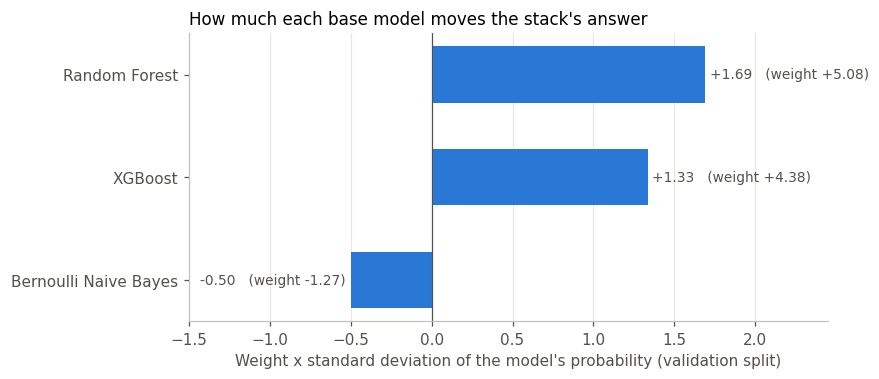

In [7]:
weights, intercept = tr.stack_weights(stack_model)
spread = base_val.std()
weights_table = pd.DataFrame({"weight": weights.values, "std of its probability (validation)": spread.values,
                              "weight x std": weights.values * spread.values}, index=[SHORT[k] for k in weights.index])
weights_table["share of total |weight x std|"] = weights_table["weight x std"].abs() / weights_table["weight x std"].abs().sum()
display(weights_table.style.format({"weight": "{:+.3f}", "std of its probability (validation)": "{:.3f}",
                                    "weight x std": "{:+.3f}", "share of total |weight x std|": "{:.1%}"}))
print(f"Intercept: {intercept:+.3f}    final estimator settings: {final_settings}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot = weights_table["weight x std"].sort_values()
bars = ax.barh(plot.index, plot.values, color=BLUE, height=0.55)
ax.bar_label(bars, labels=[f"{w:+.2f}   (weight {weights_table.loc[n, 'weight']:+.2f})" for n, w in plot.items()], color=INK, fontsize=9, padding=3)
ax.set_xlim(min(0, plot.min()) - 1.0, plot.max() * 1.45)
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlabel("Weight x standard deviation of the model's probability (validation split)")
ax.set_title("How much each base model moves the stack's answer", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "06_stack_weights.png")
plt.show()

**Reading the weights.**

- XGBoost (+4.38) and Random Forest (+5.08) get large positive weights. **Bernoulli Naive Bayes gets a negative weight (-1.27).** That is not an error. Naive Bayes is correlated with the other two (0.94 to 0.96 out-of-fold) but more extreme, so the stack uses it as a *correction*: when Naive Bayes is more optimistic than the other two, the stack lowers its answer a little.
- After allowing for how much each model's probability varies (third column), the pull is **Random Forest 48%, XGBoost 38%, Naive Bayes 14%**. The stack leans on the Random Forest more than on XGBoost even though XGBoost is the better model on its own. Because the three probabilities are so strongly correlated, a Logistic Regression can split the credit among them in many nearly equivalent ways, so the individual weights are **not a reliable ranking of the models**. What matters is the combined answer.
- The intercept (-4.15) balances the weights: if all three models said 0 the stack would answer about 2%, and if all three said 1 about 98%.

## 6. Charts

### Confusion matrices (validation split)

Rows are what really happened, columns what the model predicted. The percentages are shares of each row, so the top-left cell is the **recall of class 0**: the share of slow requests the model flagged.

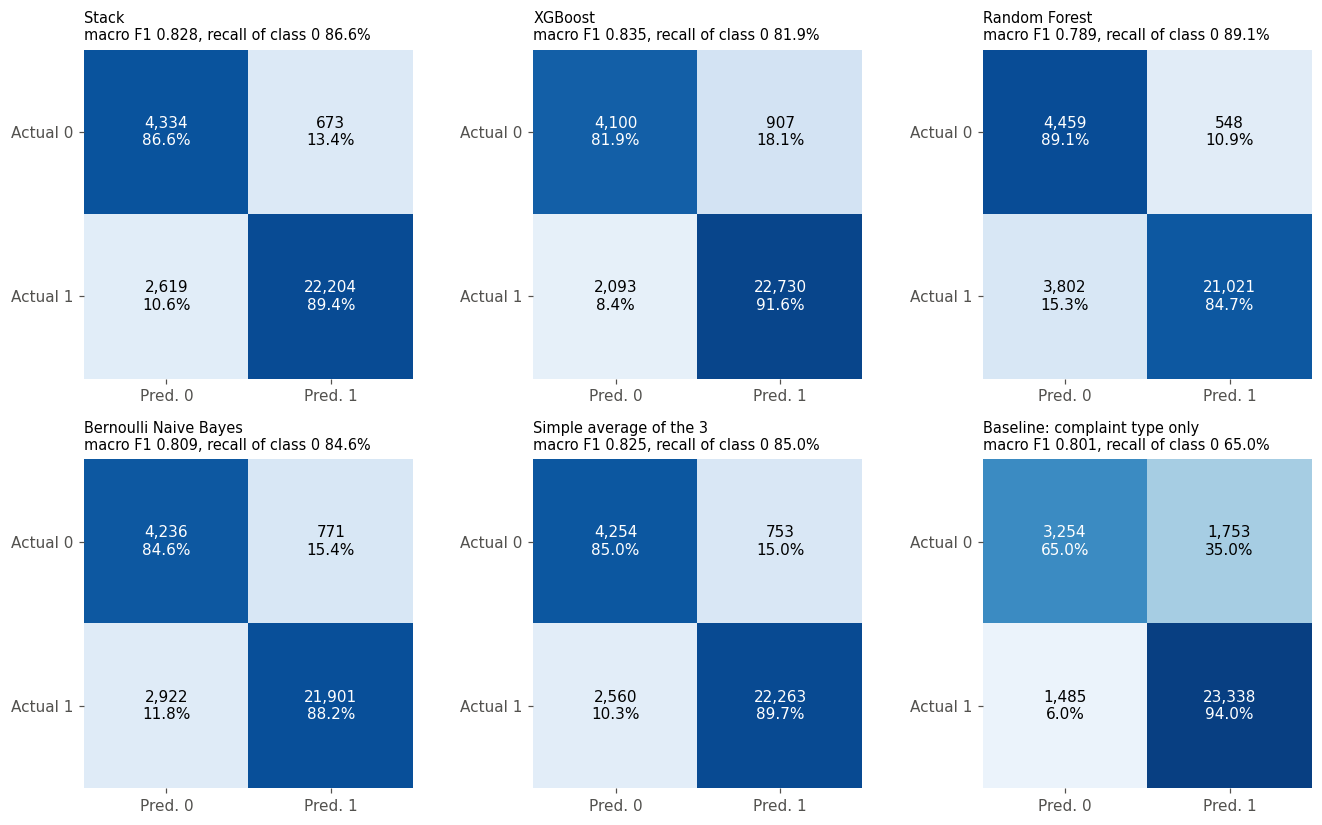

In [8]:
panels = ["Stack", "XGBoost", "Random Forest", "Bernoulli Naive Bayes", "Simple average of the 3", "Baseline: complaint type only"]
fig, axes = plt.subplots(2, 3, figsize=(12.5, 7.6))
for ax, name in zip(axes.ravel(), panels):
    plot_confusion(ax, validation.loc[name].drop("role").astype(float), name)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_validation_confusion_matrices.png")
plt.show()

### ROC curves and the main scores (validation split)

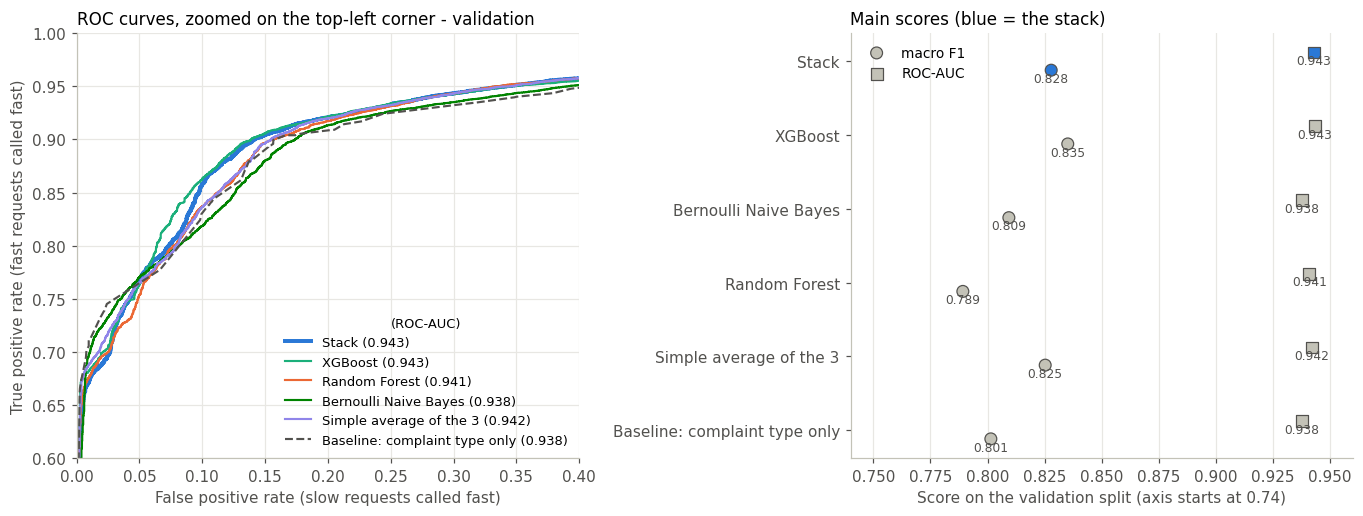

In [9]:
colors = {"Stack": BLUE, "XGBoost": AQUA, "Random Forest": ORANGE, "Bernoulli Naive Bayes": "#008300",
          "Simple average of the 3": "#9085e9", "Baseline: complaint type only": INK}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for name, color in colors.items():
    fpr, tpr, _ = roc_curve(y_val, val_probability[name])
    axes[0].plot(fpr, tpr, color=color, linewidth=2.6 if name == "Stack" else 1.4, linestyle="--" if name.startswith("Baseline") else "-",
                 label=f"{name} ({validation.loc[name, 'roc_auc']:.3f})")
axes[0].set_xlim(0, 0.4)
axes[0].set_ylim(0.6, 1.0)
axes[0].set_xlabel("False positive rate (slow requests called fast)")
axes[0].set_ylabel("True positive rate (fast requests called fast)")
axes[0].set_title("ROC curves, zoomed on the top-left corner - validation", loc="left", fontsize=11)
axes[0].legend(loc="lower right", frameon=False, fontsize=8.5, title="(ROC-AUC)", title_fontsize=8.5)

order = ["Baseline: complaint type only", "Simple average of the 3", "Random Forest", "Bernoulli Naive Bayes", "XGBoost", "Stack"]
positions = np.arange(len(order))
for score, marker, offset in [("macro_f1", "o", -0.12), ("roc_auc", "s", 0.12)]:
    axes[1].scatter([validation.loc[n, score] for n in order], positions + offset,
                    color=[BLUE if n == "Stack" else GREY for n in order], marker=marker, s=60, edgecolor=INK, linewidth=0.8, zorder=3,
                    label="macro F1" if score == "macro_f1" else "ROC-AUC")
    for n, p in zip(order, positions):
        axes[1].text(validation.loc[n, score], p + offset - 0.2, f"{validation.loc[n, score]:.3f}", ha="center", va="bottom", fontsize=8, color=INK)
axes[1].set_yticks(positions, order)
axes[1].set_xlim(0.74, 0.96)
axes[1].set_xlabel("Score on the validation split (axis starts at 0.74)")
axes[1].set_title("Main scores (blue = the stack)", loc="left", fontsize=11)
axes[1].legend(loc="upper left", frameon=False, fontsize=9)
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_validation_roc_and_scores.png")
plt.show()

## 7. Saving the fitted model

The fitted pipeline is saved to `models/model.joblib` (git ignores this file) and the other fitted models needed for the test comparison go to a scratch file, `models/_validation_models.joblib`. They are all fitted on the training split only. The test section loads **these files** and scores them, so the scores in the report belong to exactly the file that is deployed.

In [10]:
joblib.dump(stack_model, "../models/model.joblib")
joblib.dump({"XGBoost alone": xgb_alone, **baselines}, "../models/_validation_models.joblib")
size = Path("../models/model.joblib").stat().st_size / 1e6
print(f"Saved ../models/model.joblib: {size:.1f} MB")
print("Saved ../models/_validation_models.joblib (scratch: XGBoost alone and the two baselines, fitted on the training split)")
print("The test split has not been read.")

Saved ../models/model.joblib: 19.8 MB
Saved ../models/_validation_models.joblib (scratch: XGBoost alone and the two baselines, fitted on the training split)
The test split has not been read.


# 8. Scoring the test split, once

Everything above was fitted on the training split and judged on the validation split, and the results were saved and committed **before** this section was written. The validation work is therefore fixed, and nothing below can change a setting.

**What is scored.** The saved file `models/model.joblib` (the stack), its three base models (taken from inside the stack, already fitted on the training split), XGBoost alone, and the two baselines. None of them is refitted or changed.

**Once only.** The cell that reads the test split starts with a guard: it stops if `reports/test_results.csv` already exists. The probabilities it computes are saved to a scratch file so that the charts and the checks below never need to read the test split again. If something breaks after the test was scored, the fix is made in the later cells; the test is not run again and nothing is tuned from its result.

**What the test split is.** The newest 15% of requests, filed 2026-04-14 to 2026-08-31, all after the training and validation periods. It is the closest thing available to "requests the model has never seen, from the future".

In [1]:
import hashlib
import json
import platform
import subprocess
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, roc_auc_score, roc_curve

sys.path.insert(0, "..")                 # so that "src" can be imported from the notebooks folder
from src import features as ft
from src import train as tr

FIG_DIR = Path("../reports/figures")
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
})

MODEL_PATH = Path("../models/model.joblib")
TEST_RESULTS = Path("../reports/test_results.csv")
TEST_SCRATCH = Path("../models/_test_scratch.parquet")
best_settings = json.loads(Path("../reports/best_settings.json").read_text())
validation = pd.read_csv("../reports/stacking_validation.csv").set_index("model")
model = joblib.load(MODEL_PATH)                      # the file saved at the end of the validation part
scratch = joblib.load("../models/_validation_models.joblib")
print(f"Loaded {MODEL_PATH.name}: {MODEL_PATH.stat().st_size / 1e6:.1f} MB, steps {[name for name, _ in model.steps]}")

Loaded model.joblib: 19.8 MB, steps ['clean', 'stack']


In [2]:
assert not TEST_RESULTS.exists(), "The test split has already been scored. It is scored once only."

X_test, y_test = tr.load_xy("test", "../data/processed")        # the one and only read of the test split
print(f"Test split: {len(X_test):,} requests, {X_test['created_date'].min()} to {X_test['created_date'].max()}, "
      f"class 0 share {1 - y_test.mean():.1%}")

cleaned = model["clean"].transform(X_test)
base = model["stack"].named_estimators_                           # the three base models, fitted on the training split
probability = {
    "Stack": model.predict_proba(X_test)[:, 1],
    "XGBoost": scratch["XGBoost alone"].predict_proba(X_test)[:, 1],
    "Random Forest": base["random_forest"].predict_proba(cleaned)[:, 1],
    "Bernoulli Naive Bayes": base["naive_bayes"].predict_proba(cleaned)[:, 1],
    "Baseline: complaint type only": scratch["Baseline: complaint type only"].predict_proba(X_test)[:, 1],
    "Baseline: majority class": scratch["Baseline: majority class"].predict_proba(X_test)[:, 1],
}
inside = np.abs(base["xgboost"].predict_proba(cleaned)[:, 1] - probability["XGBoost"]).max()
print(f"XGBoost alone vs the copy inside the stack: largest difference in test probabilities {inside:.2e}")

roles = {"Stack": "final model", "XGBoost": "base model, best single model", "Random Forest": "base model",
         "Bernoulli Naive Bayes": "base model", "Baseline: complaint type only": "baseline", "Baseline: majority class": "baseline"}
test_results = pd.DataFrame({name: tr.evaluate_probability(y_test, p) for name, p in probability.items()}).T
test_results.insert(0, "role", pd.Series(roles))
test_results.index.name = "model"
test_results.to_csv(TEST_RESULTS)

# For the drift check below: the same probabilities for the validation rows, and the dates of the test rows
X_val, y_val = tr.load_xy("val", "../data/processed")
val_stack = model.predict_proba(X_val)[:, 1]
val_xgb = scratch["XGBoost alone"].predict_proba(X_val)[:, 1]
pd.concat([
    pd.DataFrame({**probability, "y": y_test.to_numpy(), "created_date": X_test["created_date"].to_numpy(), "split": "test"}),
    pd.DataFrame({"Stack": val_stack, "XGBoost": val_xgb, "y": y_val.to_numpy(), "created_date": X_val["created_date"].to_numpy(), "split": "val"}),
]).to_parquet(TEST_SCRATCH, index=False)
print(f"Saved {TEST_RESULTS.name} and the scratch probabilities. The test split is not read again.")

CLASS0 = ["precision_0", "recall_0", "f1_0"]
columns = ["accuracy"] + CLASS0 + ["precision_1", "recall_1", "f1_1", "macro_f1", "roc_auc"]
print(f"\nTest split, {len(y_test):,} requests ({int((y_test == 0).sum()):,} in class 0). Class 0 is highlighted.")
display(test_results[columns].astype(float).style.format("{:.4f}")
        .set_properties(subset=CLASS0, **{"background-color": "#fdebd8", "color": "black", "font-weight": "bold"})
        .highlight_max(subset=["macro_f1", "roc_auc"], props="text-decoration: underline; font-weight: bold"))
print("Confusion matrix counts")
display(test_results[["actual0_pred0", "actual0_pred1", "actual1_pred0", "actual1_pred1"]].astype(int)
        .rename(columns={"actual0_pred0": "slow, flagged (correct)", "actual0_pred1": "slow, missed",
                         "actual1_pred0": "fast, flagged by mistake", "actual1_pred1": "fast, not flagged (correct)"})
        .style.format("{:,}"))

Test split: 29,831 requests, 2026-04-14 21:11:23 to 2026-08-31 23:59:06, class 0 share 18.3%


XGBoost alone vs the copy inside the stack: largest difference in test probabilities 0.00e+00


Saved test_results.csv and the scratch probabilities. The test split is not read again.

Test split, 29,831 requests (5,468 in class 0). Class 0 is highlighted.


,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1,roc_auc
model,,,,,,,,,
Stack,0.8630,0.5838,0.8789,0.7016,0.9694,0.8594,0.9111,0.8063,0.9360
XGBoost,0.8840,0.6413,0.8338,0.7250,0.9600,0.8953,0.9265,0.8258,0.9369
Random Forest,0.8325,0.5249,0.9095,0.6656,0.9757,0.8152,0.8883,0.7769,0.9328
Bernoulli Naive Bayes,0.8568,0.5716,0.8725,0.6907,0.9676,0.8532,0.9068,0.7987,0.9281
Baseline: complaint type only,0.8805,0.6794,0.6587,0.6689,0.9239,0.9302,0.9271,0.7980,0.9267
Baseline: majority class,0.8167,0.0000,0.0000,0.0000,0.8167,1.0000,0.8991,0.4496,0.5000


Confusion matrix counts


,"slow, flagged (correct)","slow, missed","fast, flagged by mistake","fast, not flagged (correct)"
model,,,,
Stack,"4,806",662,"3,426","20,937"
XGBoost,"4,559",909,"2,550","21,813"
Random Forest,"4,973",495,"4,502","19,861"
Bernoulli Naive Bayes,"4,771",697,"3,576","20,787"
Baseline: complaint type only,"3,602","1,866","1,700","22,663"
Baseline: majority class,0,"5,468",0,"24,363"


**Reading the test results (29,831 requests, 5,468 in class 0).**

- **The stack is again below XGBoost alone on macro F1: 0.806 against 0.826, which is 1.95 points lower.** On ROC-AUC they are level (0.9360 against 0.9369, a difference of 0.09 points). As on validation, the difference is where the cut-off sits: the stack flags more slow requests (recall of class 0 87.9% against 83.4%; 662 slow requests missed against 909) and raises more false alarms (3,426 fast requests flagged against 2,550; precision of class 0 58.4% against 64.1%). Accuracy is 2.1 points lower.
- **The stack's margin over the simple baseline is small.** It is above the complaint-type-only baseline by 0.8 points of macro F1 (0.806 against 0.798) and by 0.9 points of ROC-AUC. XGBoost is 2.8 points above that baseline on macro F1.
- **The order of the models is the same as on validation:** XGBoost (0.826), the stack (0.806), Naive Bayes (0.799), the complaint-type baseline (0.798), Random Forest (0.777). The stack beats Random Forest by 2.9 points and Naive Bayes by 0.8.
- **What the stack's precision means in use.** Of the requests it flags as slow, 58.4% really took longer than 7 days; the other 41.6% were resolved within 7 days. It catches 87.9% of the requests that really did take longer.

### Validation to test: the gap

Each score on the test split minus the same score on the validation split, in **percentage points** (negative = lower on the test split). The stack and XGBoost are shown with their validation and test values side by side.

In [2]:
test_results = pd.read_csv("../reports/test_results.csv").set_index("model")
scratch_probs = pd.read_parquet(TEST_SCRATCH)

rows = []
for name in test_results.index:
    row = {"model": name}
    for metric, label in [("macro_f1", "macro F1"), ("roc_auc", "ROC-AUC"), ("accuracy", "accuracy"), ("recall_0", "class 0 recall"), ("precision_0", "class 0 precision")]:
        row[f"{label}: validation"] = validation.loc[name, metric]
        row[f"{label}: test"] = test_results.loc[name, metric]
        row[f"{label}: gap (points)"] = (test_results.loc[name, metric] - validation.loc[name, metric]) * 100
    rows.append(row)
gap = pd.DataFrame(rows).set_index("model")
fmt = {c: "{:.4f}" for c in gap.columns if "gap" not in c}
fmt.update({c: "{:+.2f}" for c in gap.columns if "gap" in c})
display(gap[[c for c in gap.columns if c.startswith(("macro F1", "ROC-AUC"))]].style.format(fmt))
display(gap[[c for c in gap.columns if c.startswith(("accuracy", "class 0"))]].style.format(fmt))

test_part, val_part = scratch_probs[scratch_probs["split"] == "test"], scratch_probs[scratch_probs["split"] == "val"]
print(f"Class 0 share:  training 17.2%   validation {1 - val_part['y'].mean():.1%}   test {1 - test_part['y'].mean():.1%}")

,macro F1: validation,macro F1: test,macro F1: gap (points),ROC-AUC: validation,ROC-AUC: test,ROC-AUC: gap (points)
model,,,,,,
Stack,0.8279,0.8063,-2.15,0.9429,0.9360,-0.70
XGBoost,0.8351,0.8258,-0.94,0.9433,0.9369,-0.64
Random Forest,0.7892,0.7769,-1.23,0.9408,0.9328,-0.81
Bernoulli Naive Bayes,0.8093,0.7987,-1.06,0.9377,0.9281,-0.96
Baseline: complaint type only,0.8014,0.7980,-0.35,0.9377,0.9267,-1.10
Baseline: majority class,0.4542,0.4496,-0.46,0.5000,0.5000,+0.00


,accuracy: validation,accuracy: test,accuracy: gap (points),class 0 recall: validation,class 0 recall: test,class 0 recall: gap (points),class 0 precision: validation,class 0 precision: test,class 0 precision: gap (points)
model,,,,,,,,,
Stack,0.8896,0.8630,-2.67,0.8656,0.8789,+1.33,0.6233,0.5838,-3.95
XGBoost,0.8994,0.8840,-1.54,0.8189,0.8338,+1.49,0.6620,0.6413,-2.07
Random Forest,0.8542,0.8325,-2.17,0.8906,0.9095,+1.89,0.5398,0.5249,-1.49
Bernoulli Naive Bayes,0.8762,0.8568,-1.94,0.8460,0.8725,+2.65,0.5918,0.5716,-2.02
Baseline: complaint type only,0.8915,0.8805,-1.10,0.6499,0.6587,+0.89,0.6866,0.6794,-0.73
Baseline: majority class,0.8321,0.8167,-1.54,0.0000,0.0000,+0.00,0.0000,0.0000,+0.00


Class 0 share:  training 17.2%   validation 16.8%   test 18.3%


### Is the gap a drift in the data?

A drop from validation to test can come from the model, or from the requests themselves changing. Month by month, for the stack and for XGBoost (the validation months are December 2025 to April 2026, the test months April to August 2026; April is split between the two). Class 0 share is the share of requests that took longer than 7 days. These numbers are only a description of what happened; nothing is tuned from them.

month,split,requests,class 0 share,stack macro F1,XGBoost macro F1,stack ROC-AUC,stack class 0 recall,stack class 0 precision
2025-12,val,"6,369",13.9%,0.836,0.841,0.963,93.1%,60.1%
2026-01,val,"7,108",18.0%,0.841,0.842,0.947,87.9%,65.2%
2026-02,val,"6,744",16.2%,0.834,0.846,0.942,87.5%,62.9%
2026-03,val,"6,870",17.9%,0.802,0.812,0.923,80.5%,60.0%
2026-04,test,"3,322",18.7%,0.822,0.830,0.935,85.8%,62.4%
2026-04,val,"2,739",18.7%,0.826,0.835,0.937,84.4%,64.0%
2026-05,test,"6,603",16.8%,0.806,0.809,0.933,85.7%,58.0%
2026-06,test,"6,675",15.6%,0.784,0.795,0.928,86.5%,52.9%
2026-07,test,"6,749",19.9%,0.828,0.846,0.942,88.8%,63.2%
2026-08,test,"6,482",20.9%,0.796,0.844,0.942,90.8%,57.2%


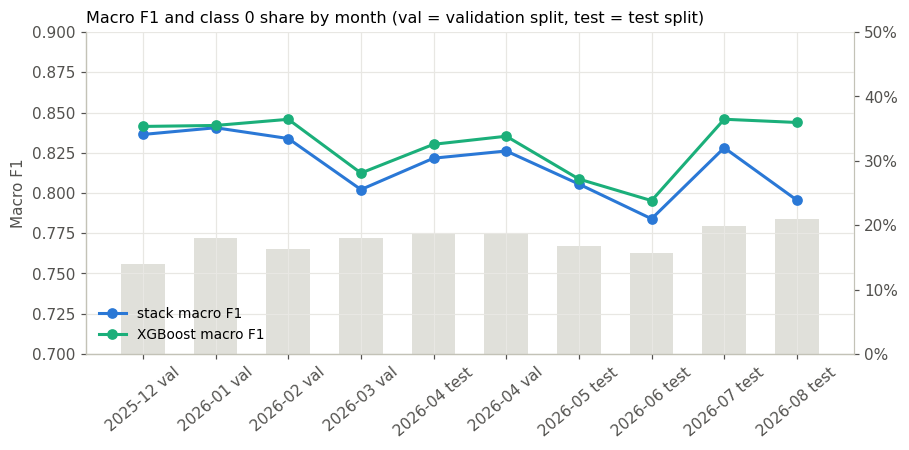

In [3]:
scratch_probs["month"] = pd.to_datetime(scratch_probs["created_date"]).dt.to_period("M")
rows = []
for (month, split), g in scratch_probs.groupby(["month", "split"]):
    rows.append({"month": str(month), "split": split, "requests": len(g), "class 0 share": 1 - g["y"].mean(),
                 "stack macro F1": f1_score(g["y"], g["Stack"] > 0.5, average="macro"),
                 "XGBoost macro F1": f1_score(g["y"], g["XGBoost"] > 0.5, average="macro"),
                 "stack ROC-AUC": roc_auc_score(g["y"], g["Stack"]),
                 "stack class 0 recall": ((g["Stack"] <= 0.5) & (g["y"] == 0)).sum() / (g["y"] == 0).sum(),
                 "stack class 0 precision": ((g["Stack"] <= 0.5) & (g["y"] == 0)).sum() / max((g["Stack"] <= 0.5).sum(), 1)})
monthly = pd.DataFrame(rows).sort_values(["month", "split"])
display(monthly.style.format({"requests": "{:,}", "class 0 share": "{:.1%}", "stack macro F1": "{:.3f}", "XGBoost macro F1": "{:.3f}",
                              "stack ROC-AUC": "{:.3f}", "stack class 0 recall": "{:.1%}", "stack class 0 precision": "{:.1%}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 3.8))
for name, color in [("stack macro F1", BLUE), ("XGBoost macro F1", AQUA)]:
    ax.plot(monthly["month"] + " " + monthly["split"], monthly[name], marker="o", color=color, linewidth=2, label=name)
ax2 = ax.twinx()
ax2.bar(monthly["month"] + " " + monthly["split"], monthly["class 0 share"], color=GREY, alpha=0.5, width=0.6, label="class 0 share (right axis)")
ax2.set_ylim(0, 0.5)
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)
ax.set_ylim(0.7, 0.9)
ax.set_ylabel("Macro F1")
ax.set_title("Macro F1 and class 0 share by month (val = validation split, test = test split)", loc="left", fontsize=10.5)
ax.tick_params(axis="x", rotation=40)
ax.legend(loc="lower left", frameon=False, fontsize=9)
fig.savefig(FIG_DIR / "06_monthly_drift.png")
plt.show()

**Explaining the gap (nothing was tuned from it).** Macro F1 of the stack fell by 2.15 points from validation to test, and ROC-AUC by 0.70 points. The evidence in the tables above points to a mix of the following.

1. **Every model got a little worse, so this is a shift in the data, not one broken model.** Macro F1 fell for all six rows, by 0.35 points (complaint-type baseline) to 2.15 points (stack). ROC-AUC fell for all five scored models, by 0.64 to 1.10 points. The complaint-type baseline, which has nothing to overfit, lost the most ROC-AUC (1.10 points).
2. **The test period has more slow requests.** The class 0 share is 18.3% on test, against 16.8% on validation and 17.2% on training. A larger rare class lowers accuracy and the precision of class 0 even if the model did not change. Month by month it rose to 19.9% in July and 20.9% in August 2026.
3. **The stack lost more than XGBoost (2.15 against 0.94 points), and the extra loss is in false alarms.** The share of fast requests wrongly flagged as slow rose from 10.6% to 14.1% for the stack, and from 8.4% to 10.5% for XGBoost. The stack's cut-off is generous because its final estimator weights the rare class, so more of the shift shows up as false alarms. This is consistent with the numbers, but it is an interpretation, not something this test can prove.
4. **Months differ a lot within each split.** The stack's monthly macro F1 ranges from 0.802 to 0.841 on validation months and from 0.784 to 0.828 on test months, a spread of about 4 points in each. July 2026 (0.828) is as good as the best validation months; June 2026 (0.784) is the weakest month of all; March 2026, in the validation split, is nearly as weak (0.802). The 2.15-point gap is about half of the normal month-to-month movement. The largest stack-versus-XGBoost difference is in August 2026 (0.796 against 0.844), when the class 0 share was highest.
5. **A selection effect is too small to explain it.** The stack's final-estimator setting was chosen on the validation split (six settings), while XGBoost's settings were chosen by cross-validation on the training split. That can make the stack's validation score slightly optimistic, but the six settings differed by at most 0.4 points of macro F1, far less than the 1.2 points by which the stack's drop exceeds XGBoost's.

**This is a finding, not a defect to fix.** The test split is the best available estimate of how the model will behave on new requests. In use, expect the stack's macro F1 to be roughly 0.78 to 0.84 depending on the month, and its ROC-AUC about 0.93 to 0.94, with more false alarms than XGBoost alone would give.

### Charts: the stack on the test split

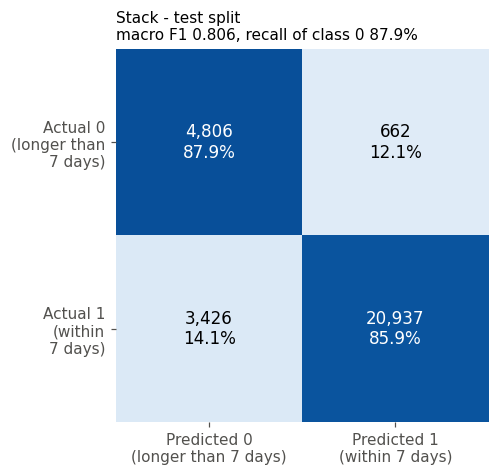

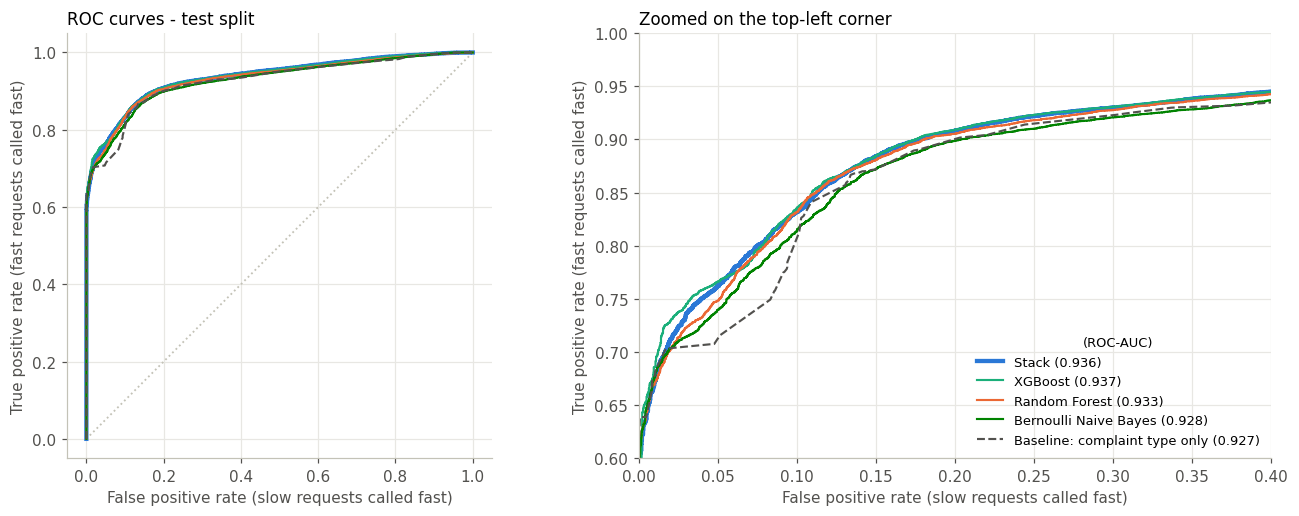

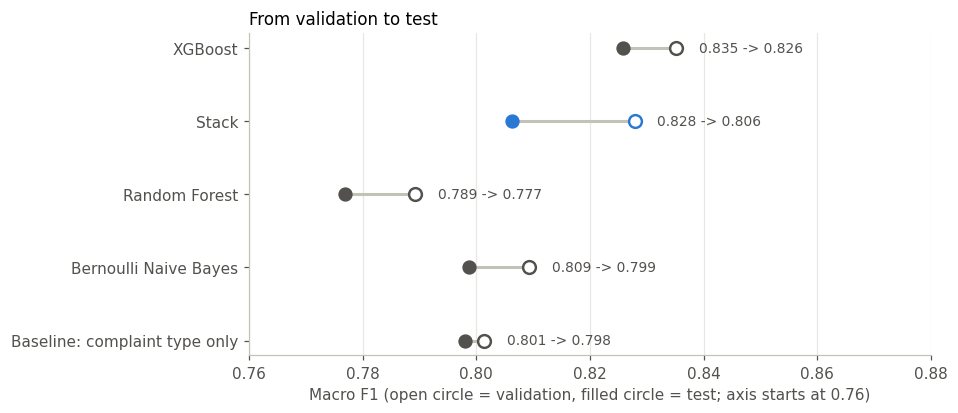

In [4]:
row = test_results.loc["Stack"]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
plot_counts = np.array([[row["actual0_pred0"], row["actual0_pred1"]], [row["actual1_pred0"], row["actual1_pred1"]]], dtype=float)
shares = plot_counts / plot_counts.sum(axis=1, keepdims=True)
ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{int(plot_counts[i, j]):,}\n{shares[i, j]:.1%}", ha="center", va="center", fontsize=11,
                color="white" if shares[i, j] > 0.55 else "black")
ax.set_xticks([0, 1], ["Predicted 0\n(longer than 7 days)", "Predicted 1\n(within 7 days)"])
ax.set_yticks([0, 1], ["Actual 0\n(longer than\n7 days)", "Actual 1\n(within\n7 days)"])
ax.set_title(f"Stack - test split\nmacro F1 {row['macro_f1']:.3f}, recall of class 0 {row['recall_0']:.1%}", loc="left", fontsize=10)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
fig.savefig(FIG_DIR / "06_test_confusion_stack.png")
plt.show()

colors = {"Stack": BLUE, "XGBoost": AQUA, "Random Forest": ORANGE, "Bernoulli Naive Bayes": "#008300", "Baseline: complaint type only": INK}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
y_t = test_part["y"].to_numpy()
for ax, zoom in zip(axes, [False, True]):
    ax.plot([0, 1], [0, 1], color=GREY, linewidth=1.2, linestyle=":")
    for name, color in colors.items():
        fpr, tpr, _ = roc_curve(y_t, test_part[name])
        ax.plot(fpr, tpr, color=color, linewidth=2.8 if name == "Stack" else 1.4, linestyle="--" if name.startswith("Baseline") else "-",
                label=f"{name} ({test_results.loc[name, 'roc_auc']:.3f})")
    ax.set_xlabel("False positive rate (slow requests called fast)")
    ax.set_ylabel("True positive rate (fast requests called fast)")
    if zoom:
        ax.set_xlim(0, 0.4)
        ax.set_ylim(0.6, 1.0)
        ax.set_title("Zoomed on the top-left corner", loc="left", fontsize=11)
        ax.legend(loc="lower right", frameon=False, fontsize=8.5, title="(ROC-AUC)", title_fontsize=8.5)
    else:
        ax.set_title("ROC curves - test split", loc="left", fontsize=11)
        ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_test_roc_curves.png")
plt.show()

order = ["Baseline: complaint type only", "Bernoulli Naive Bayes", "Random Forest", "Stack", "XGBoost"]
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, name in enumerate(order):
    ax.plot([validation.loc[name, "macro_f1"], test_results.loc[name, "macro_f1"]], [i, i], color=GREY, linewidth=2, zorder=1)
    ax.scatter(validation.loc[name, "macro_f1"], i, color="white", edgecolor=BLUE if name == "Stack" else INK, s=70, zorder=3, linewidth=1.6)
    ax.scatter(test_results.loc[name, "macro_f1"], i, color=BLUE if name == "Stack" else INK, s=70, zorder=3)
    ax.text(max(validation.loc[name, "macro_f1"], test_results.loc[name, "macro_f1"]) + 0.004, i,
            f"{validation.loc[name, 'macro_f1']:.3f} -> {test_results.loc[name, 'macro_f1']:.3f}", va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(order)), order)
ax.set_xlim(0.76, 0.88)
ax.set_xlabel("Macro F1 (open circle = validation, filled circle = test; axis starts at 0.76)")
ax.set_title("From validation to test", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "06_validation_vs_test.png")
plt.show()

# 9. The deployable files

Written now, after the test scoring. None of the files below reads the test split: the sample requests come from the **validation** split, and the test split's dates and row count come from the scratch file made by the single test read.

| File | What it holds |
| --- | --- |
| `models/model.joblib` | the full pipeline (already saved above; git ignores it, copy it to EC2 with `scp`) |
| `models/model_meta.json` | SHA-256 of the model, library versions, the fields the API must receive, label meaning, split dates, final-estimator settings |
| `models/metrics.json` | validation and test metrics of the stack, file size, time to predict one request |
| `data/sample_requests.json` | 5 real raw requests from the validation split, and 3 deliberately invalid ones |

In [5]:
import importlib.metadata as metadata
from datetime import datetime

sha256 = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
size_mb = MODEL_PATH.stat().st_size / 1e6
import sklearn, xgboost
versions = {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
            "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__}
print("SHA-256:", sha256)
print(f"File size: {size_mb:.2f} MB")
print("Versions:", versions)

# Which part of the file is large?
parts = {}
import io
for key, estimator in model["stack"].named_estimators_.items():
    buffer = io.BytesIO()
    joblib.dump(estimator, buffer)
    parts[tr.STACK_MODELS[key]] = len(buffer.getvalue()) / 1e6
buffer = io.BytesIO()
joblib.dump(model["stack"].final_estimator_, buffer)
parts["Final estimator (Logistic Regression)"] = len(buffer.getvalue()) / 1e6
buffer = io.BytesIO()
joblib.dump(model["clean"], buffer)
parts["Cleaning step (category lists)"] = len(buffer.getvalue()) / 1e6
display(pd.Series(parts, name="MB").to_frame().style.format("{:.2f}"))
print(f"The file is {size_mb:.1f} MB, well below the 60 MB limit I was asked to watch. "
      f"The Random Forest is {parts['Random Forest'] / size_mb:.0%} of it.")

SHA-256: f96047169d3e737d29ed23ab85fc09bf2afced7e6c9463514993a4fb3f68d1b5
File size: 19.82 MB
Versions: {'python': '3.10.10', 'scikit-learn': '1.7.2', 'xgboost': '3.2.0', 'pandas': '2.3.3', 'numpy': '2.2.6', 'joblib': '1.6.0'}


,MB
XGBoost,1.80
Bernoulli Naive Bayes,0.04
Random Forest,17.95
Final estimator (Logistic Regression),0.00
Cleaning step (category lists),0.01


The file is 19.8 MB, well below the 60 MB limit I was asked to watch. The Random Forest is 91% of it.


In [6]:
# 5 realistic requests from the VALIDATION split, with raw values exactly as the city's data has them
raw = pd.read_parquet("../data/raw/nyc311_raw.parquet").set_index("unique_key")
val_clean = pd.read_parquet("../data/processed/val.parquet")           # the validation split only
pool = val_clean[["unique_key", "created_date", "resolved_within_7d", "complaint_type"]].copy()
pool = pool.join(raw[["complaint_type", "descriptor", "location_type", "borough", "incident_zip",
                      "open_data_channel_type", "latitude", "longitude", "created_date"]]
                 .rename(columns=lambda c: "raw_" + c), on="unique_key")
common = val_clean["complaint_type"].value_counts().head(12).index
pool = pool[pool["complaint_type"].isin(common) & pool["raw_descriptor"].notna() & pool["raw_location_type"].notna()
            & (pool["raw_borough"] != "Unspecified") & (pool["raw_open_data_channel_type"] != "UNKNOWN")]
pool = pool.sample(frac=1, random_state=42)                            # fixed shuffle

picks, used = [], set()
def pick(label, need_missing_coordinates=False):
    for _, row in pool.iterrows():
        if row["resolved_within_7d"] != label or row["complaint_type"] in used or row["unique_key"] in {p["unique_key"] for p in picks}:
            continue
        if need_missing_coordinates and pd.notna(row["raw_latitude"]):
            continue
        if not need_missing_coordinates and pd.isna(row["raw_latitude"]):
            continue
        used.add(row["complaint_type"])
        picks.append(row)
        return
    raise RuntimeError("no suitable validation row found")

for label, missing in [(1, False), (1, False), (1, True), (0, False), (0, False)]:
    pick(label, missing)

def to_request(row):
    def value(x):
        return None if pd.isna(x) else x
    created = pd.to_datetime(row["raw_created_date"]).isoformat(timespec="seconds")
    return {"complaint_type": row["raw_complaint_type"], "descriptor": value(row["raw_descriptor"]),
            "location_type": value(row["raw_location_type"]), "borough": row["raw_borough"],
            "incident_zip": value(row["raw_incident_zip"]),
            "open_data_channel_type": row["raw_open_data_channel_type"],
            "latitude": None if pd.isna(row["raw_latitude"]) else round(float(row["raw_latitude"]), 6),
            "longitude": None if pd.isna(row["raw_longitude"]) else round(float(row["raw_longitude"]), 6),
            "created_at": created}

valid = []
for number, row in enumerate(picks, 1):
    request = to_request(row)
    probability = float(model.predict_proba(pd.DataFrame([request]))[0, 1])
    valid.append({"name": f"validation_example_{number}", "source": f"validation split, unique_key {row['unique_key']}",
                  "request": request, "true_label": int(row["resolved_within_7d"]),
                  "expected_predicted_class": int(probability > 0.5),
                  "expected_probability_within_threshold": round(probability, 12)})

# The same rows through the validation batch path must give the same probabilities
X_val_all, y_val_all = tr.load_xy("val", "../data/processed")
batch_probability = pd.Series(model.predict_proba(X_val_all)[:, 1], index=val_clean["unique_key"].values)
for item, row in zip(valid, picks):
    difference = abs(batch_probability.loc[row["unique_key"]] - item["expected_probability_within_threshold"])
    assert difference < 1e-9, difference
print("Probabilities from the raw request dicts equal those from the validation batch for the same rows (difference below 1e-9).")

invalid = [
    {"name": "missing_required_field", "reason": "borough is required and is missing",
     "request": {k: v for k, v in valid[0]["request"].items() if k != "borough"},
     "expected_status": 422, "expected_error_field": "borough"},
    {"name": "wrong_type", "reason": "latitude must be a number but is text",
     "request": {**valid[1]["request"], "latitude": "north of the park"},
     "expected_status": 422, "expected_error_field": "latitude"},
    {"name": "impossible_coordinate", "reason": "a latitude cannot be 140.7 (latitudes run from -90 to 90; New York is about 40.7)",
     "request": {**valid[0]["request"], "latitude": 140.7},
     "expected_status": 422, "expected_error_field": "latitude"},
]

samples = {
    "description": "Raw requests in the format of the API (CLAUDE.md section 6), with the model's answer. valid_requests come from the "
                   "VALIDATION split (the test split was not used); invalid_requests must be rejected by the API with the status shown.",
    "label_meaning": {"1": "resolved within 7 days", "0": "not resolved within 7 days"},
    "valid_requests": valid, "invalid_requests": invalid,
}
Path("../data/sample_requests.json").write_text(json.dumps(samples, indent=2), encoding="utf-8")

table = pd.DataFrame([{"example": v["name"], "complaint_type": v["request"]["complaint_type"], "borough": v["request"]["borough"],
                       "channel": v["request"]["open_data_channel_type"], "has coordinates": v["request"]["latitude"] is not None,
                       "true label": v["true_label"], "probability within 7 days": v["expected_probability_within_threshold"],
                       "predicted class": v["expected_predicted_class"]} for v in valid])
display(table.style.format({"probability within 7 days": "{:.4f}"}).hide(axis="index"))
print("Saved ../data/sample_requests.json")
print(json.dumps(valid[2]["request"], indent=2))

Probabilities from the raw request dicts equal those from the validation batch for the same rows (difference below 1e-9).


example,complaint_type,borough,channel,has coordinates,true label,probability within 7 days,predicted class
validation_example_1,Blocked Driveway,STATEN ISLAND,PHONE,True,1,0.9824,1
validation_example_2,Illegal Parking,QUEENS,ONLINE,True,1,0.9826,1
validation_example_3,Snow or Ice,BROOKLYN,ONLINE,False,1,0.4788,0
validation_example_4,UNSANITARY CONDITION,BRONX,PHONE,True,0,0.1234,0
validation_example_5,PLUMBING,BROOKLYN,PHONE,True,0,0.0791,0


Saved ../data/sample_requests.json
{
  "complaint_type": "Snow or Ice",
  "descriptor": "Roadway",
  "location_type": "Street",
  "borough": "BROOKLYN",
  "incident_zip": "11228",
  "open_data_channel_type": "ONLINE",
  "latitude": null,
  "longitude": null,
  "created_at": "2026-02-25T16:24:03"
}


In [7]:
# Latency of one prediction from a raw request dict (median of 20 calls, after one warm-up call)
one_request = pd.DataFrame([valid[0]["request"]])
import copy, timeit
latency_ms = tr.predict_one_ms(model, one_request, repeats=60)
clean_ms = float(np.median([timeit.timeit(lambda: model["clean"].transform(one_request), number=1) * 1000 for _ in range(60)]))
cleaned_one = model["clean"].transform(one_request)
part_ms = {tr.STACK_MODELS[k]: float(np.median([timeit.timeit(lambda: e.predict_proba(cleaned_one), number=1) * 1000 for _ in range(60)]))
           for k, e in model["stack"].named_estimators_.items()}
print(f"One prediction, whole pipeline: {latency_ms:.1f} ms (median of 60 calls). This is the model only, without the web server.")
print(f"  cleaning step {clean_ms:.1f} ms; base models: " + ", ".join(f"{k} {v:.1f} ms" for k, v in part_ms.items()))

# The Random Forest was fitted with n_jobs=-1 (all cores). For ONE request, starting threads costs more than it saves.
single_thread = copy.deepcopy(model)
single_thread["stack"].named_estimators_["random_forest"]["model"].n_jobs = 1
assert abs(single_thread.predict_proba(one_request)[0, 1] - model.predict_proba(one_request)[0, 1]) < 1e-12
latency_one_thread_ms = tr.predict_one_ms(single_thread, one_request, repeats=60)
print(f"Same answer with the Random Forest on one thread, in {latency_one_thread_ms:.1f} ms. "
      "The API can set this when it loads the model; the saved file is not changed.")

test_row, val_row = pd.read_csv("../reports/test_results.csv").set_index("model").loc["Stack"], validation.loc["Stack"]
metric_keys = ["accuracy", "precision_0", "recall_0", "f1_0", "precision_1", "recall_1", "f1_1", "macro_f1", "roc_auc",
               "actual0_pred0", "actual0_pred1", "actual1_pred0", "actual1_pred1"]
as_dict = lambda r: {k: (int(r[k]) if k.startswith("actual") else round(float(r[k]), 6)) for k in metric_keys}
metrics = {
    "model": "CivicAI stacking classifier (XGBoost + Bernoulli Naive Bayes + Random Forest, Logistic Regression final estimator)",
    "decision_threshold": 0.5, "class_0_meaning": "not resolved within 7 days (the class staff want to flag)",
    "validation": {"requests": int(val_row[["actual0_pred0", "actual0_pred1", "actual1_pred0", "actual1_pred1"]].sum()), **as_dict(val_row)},
    "test": {"requests": int(test_row[["actual0_pred0", "actual0_pred1", "actual1_pred0", "actual1_pred1"]].sum()), **as_dict(test_row)},
    "validation_to_test_gap_points": {k: round((float(test_row[k]) - float(val_row[k])) * 100, 3) for k in ["accuracy", "precision_0", "recall_0", "f1_0", "macro_f1", "roc_auc"]},
    "xgboost_alone": {"validation_macro_f1": round(float(validation.loc["XGBoost", "macro_f1"]), 6), "test_macro_f1": round(float(test_results.loc["XGBoost", "macro_f1"]), 6),
                      "validation_roc_auc": round(float(validation.loc["XGBoost", "roc_auc"]), 6), "test_roc_auc": round(float(test_results.loc["XGBoost", "roc_auc"]), 6)},
    "file_size_mb": round(size_mb, 3),
    "predict_one_request_ms": round(latency_ms, 1),
    "predict_one_request_ms_random_forest_one_thread": round(latency_one_thread_ms, 1),
    "predict_one_request_note": "median of 60 calls on the development laptop, model only (no web server), one raw request dict. "
                                "The second figure sets the Random Forest to n_jobs=1 after loading, which gives identical answers.",
}
Path("../models/metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print("Saved ../models/metrics.json")
display(pd.DataFrame({"validation": metrics["validation"], "test": metrics["test"]}).T[["macro_f1", "roc_auc", "accuracy", "precision_0", "recall_0"]].style.format("{:.4f}"))

One prediction, whole pipeline: 107.8 ms (median of 60 calls). This is the model only, without the web server.
  cleaning step 23.7 ms; base models: XGBoost 10.2 ms, Bernoulli Naive Bayes 7.9 ms, Random Forest 30.9 ms


Same answer with the Random Forest on one thread, in 79.8 ms. The API can set this when it loads the model; the saved file is not changed.
Saved ../models/metrics.json


,macro_f1,roc_auc,accuracy,precision_0,recall_0
validation,0.8279,0.9429,0.8896,0.6233,0.8656
test,0.8063,0.9360,0.8630,0.5838,0.8789


In [8]:
kept = model["clean"].values_["kept_categories"]
weights, intercept = tr.stack_weights(model)
scratch_probs = pd.read_parquet(TEST_SCRATCH)
train_part, val_part2 = pd.read_parquet("../data/processed/train.parquet"), pd.read_parquet("../data/processed/val.parquet")
test_dates = scratch_probs[scratch_probs["split"] == "test"]
split_info = {"train": {"rows": len(train_part), "from": str(train_part["created_date"].min()), "to": str(train_part["created_date"].max())},
              "validation": {"rows": len(val_part2), "from": str(val_part2["created_date"].min()), "to": str(val_part2["created_date"].max())},
              "test": {"rows": len(test_dates), "from": str(test_dates["created_date"].min()), "to": str(test_dates["created_date"].max())}}
for name, part in [("train", split_info["train"]), ("validation", split_info["validation"]), ("test", split_info["test"])]:
    print(f"{name:10s} {part['rows']:,} rows  {part['from']}  to  {part['to']}")

def text_field(name, required, description, example, known=None):
    field = {"name": name, "type": "string", "required": required, "description": description, "example": example}
    if known is not None:
        field["known_values_count"] = len(known)
        if len(known) <= 40:
            field["known_values"] = known
    return field

input_fields = [
    text_field("complaint_type", True, "Kind of request, as in the NYC 311 data. Any case or spacing is accepted. A type the model has never seen is treated as 'Other'.", "Noise - Residential", kept["complaint_type"]),
    text_field("borough", True, "One of the five boroughs. Any case is accepted; anything else is treated as 'Unknown'.", "BROOKLYN", [b for b in kept["borough"] if b != ft.pp.UNKNOWN]),
    text_field("open_data_channel_type", True, "How the request was filed.", "PHONE", kept["open_data_channel_type"]),
    {"name": "created_at", "type": "string (ISO 8601 date and time, no time zone needed)", "required": True,
     "description": "When the request was filed. The server derives hour, weekday, month and the weekend flag from it.", "example": "2026-11-09T22:15:00"},
    text_field("descriptor", False, "More detail about the complaint. Missing becomes 'Unknown'; unseen text becomes 'Other'.", "Loud Music/Party", kept["descriptor"]),
    text_field("location_type", False, "Kind of place. Missing becomes 'Unknown'; unseen text becomes 'Other'.", "Residential Building/House", kept["location_type"]),
    text_field("incident_zip", False, "5-digit New York ZIP code, as text. An invalid ZIP becomes 'Unknown'; a ZIP not among the common ones becomes 'Other'.", "11201", kept["incident_zip"]),
    {"name": "latitude", "type": "number", "required": False,
     "description": "Missing is allowed. Phase 7 should reject values that are impossible (outside -90..90) with HTTP 422; values inside that range but outside the New York box below are treated as missing by the cleaning step.",
     "valid_range_new_york": [ft.pp.NYC_LAT_RANGE[0], ft.pp.NYC_LAT_RANGE[1]], "example": 40.69},
    {"name": "longitude", "type": "number", "required": False,
     "description": "Missing is allowed; same rules as latitude (impossible means outside -180..180). If only one of latitude and longitude is given, both are treated as missing.",
     "valid_range_new_york": [ft.pp.NYC_LON_RANGE[0], ft.pp.NYC_LON_RANGE[1]], "example": -73.99},
]
assert len(input_fields) == 9

meta = {
    "model_name": "CivicAI stacking classifier", "model_version": "1.0",
    "trained_on": datetime.now().strftime("%Y-%m-%d"), "random_state": 42,
    "file": "models/model.joblib", "sha256": sha256, "file_size_mb": round(size_mb, 3),
    "versions": versions,
    "requires_on_server": ["src/__init__.py", "src/preprocessing.py", "src/features.py", "models/model.joblib", "models/model_meta.json"],
    "start_from": "the project root, so that the package 'src' can be imported",
    "label": {"1": "resolved within 7 days", "0": "not resolved within 7 days", "threshold_days": 7,
              "predict_proba_column_1": "probability of class 1 (resolved within 7 days)", "decision_threshold": 0.5},
    "input_fields": input_fields,
    "input_fields_note": "The API receives 9 raw fields. The model uses 12 features: 8 of these fields plus hour, weekday, month and is_weekend, which are derived from created_at.",
    "model_features": list(ft.FINAL_FEATURES),
    "pipeline": {"step 1 clean": "RequestCleaner (src/features.py): the Phase 3 cleaning, rare categories to 'Other', time features",
                 "step 2 stack": "StackingClassifier over three base models, each with its own encoder",
                 "base_models": {tr.STACK_MODELS[k]: best_settings[tr.STACK_MODELS[k]] for k in tr.STACK_MODELS},
                 "stack_cv": "StratifiedKFold(n_splits=5, shuffle=True, random_state=42), inside the training split only",
                 "stack_method": "predict_proba", "passthrough": False},
    "final_estimator": {"type": "LogisticRegression", **best_settings[tr.STACK_FINAL_KEY], "max_iter": 3000,
                        "weights": {tr.STACK_MODELS[k]: round(float(w), 6) for k, w in weights.items()}, "intercept": round(intercept, 6),
                        "chosen_by": "validation macro F1, grid in reports/stacking_tuning.csv"},
    "split": split_info,
    "fitted_on": "the training split only (not refitted on train + validation)",
}
Path("../models/model_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
print("Saved ../models/model_meta.json")
print("Fields the API must receive:", [(f["name"], "required" if f["required"] else "optional") for f in input_fields])

train      139,206 rows  2024-01-01 00:00:00  to  2025-12-02 20:45:49
validation 29,830 rows  2025-12-02 20:48:18  to  2026-04-14 21:10:06
test       29,831 rows  2026-04-14 21:11:23  to  2026-08-31 23:59:06
Saved ../models/model_meta.json
Fields the API must receive: [('complaint_type', 'required'), ('borough', 'required'), ('open_data_channel_type', 'required'), ('created_at', 'required'), ('descriptor', 'optional'), ('location_type', 'optional'), ('incident_zip', 'optional'), ('latitude', 'optional'), ('longitude', 'optional')]


# 10. Round-trip check in a fresh Python process

The check runs `src/check_saved_model.py` in a **new** Python process started with `python -I` (isolated mode: no environment variables, no user site-packages, no current folder on the path). Nothing from this notebook is available to it. It loads `models/model.joblib` from disk, sends each of the 5 sample requests as a raw dict, and compares the probabilities with the ones this notebook stored in `data/sample_requests.json`. It also checks the SHA-256 and the library versions in `model_meta.json`.

In [9]:
root = Path("..").resolve()
result = subprocess.run([sys.executable, "-I", str(root / "src" / "check_saved_model.py"), str(root)],
                        capture_output=True, text=True, cwd=str(root))
print(result.stdout)
if result.stderr.strip():
    print("stderr:", result.stderr[-1500:])
assert result.returncode == 0, "round-trip check failed"
print("Round-trip check passed in a fresh process.")

Python 3.10.10, scikit-learn 1.7.2, xgboost 3.2.0, pandas 2.3.3, numpy 2.2.6, joblib 1.6.0
Project root: D:\Personal Folder\American University of Phnom Penh\Fall 2026\Cloud Machine Learning\ML-Final-Project

PASS  SHA-256 of model.joblib matches model_meta.json (f96047169d3e737d...)
PASS  file size 19.8 MB is below 60 MB
PASS  scikit-learn 1.7.2 equals the version in model_meta.json (1.7.2)
PASS  only the project modules were needed: ['src', 'src.features', 'src.preprocessing']
PASS  validation_example_1: probability 0.982436 (notebook 0.982436), class 1, true label 1
PASS  validation_example_2: probability 0.982577 (notebook 0.982577), class 1, true label 1
PASS  validation_example_3: probability 0.478781 (notebook 0.478781), class 0, true label 1
PASS  validation_example_4: probability 0.123360 (notebook 0.123360), class 0, true label 0
PASS  validation_example_5: probability 0.079073 (notebook 0.079073), class 0, true label 0
PASS  the five requests sent together give the same prob

**What the checks show, and what Phase 7 needs to know.**

- **The saved file is the evaluated model.** A fresh process loaded `models/model.joblib`, the SHA-256 matched, and the five sample requests, sent as raw dicts, gave the same probabilities as this notebook (to 9 decimal places). One of them, `validation_example_3` (Snow or Ice, no coordinates), has a true label of 1 but a probability of 0.479, just under the 0.5 cut-off. It is a realistic example of a miss.
- **Size and speed.** The file is 19.8 MB, of which the Random Forest is 17.95 MB (91%); XGBoost is 1.8 MB and the rest is negligible. One prediction takes roughly 90 to 110 ms on this laptop (the timing varies a little from run to run; cleaning is about 23 ms, the Random Forest about 31 ms, XGBoost and Naive Bayes about 8 ms each). If the API sets the Random Forest to one thread when it loads the model, the same answer takes roughly 60 to 80 ms.
- **The model does not validate its input.** The three invalid sample requests (missing borough, text in latitude, latitude 140.7) all still receive a probability. The API in Phase 7 must reject them with HTTP 422 and name the field.
- **The API receives 9 raw fields, not 12.** The model uses 12 features, but four of them (hour, weekday, month, weekend flag) are derived from `created_at`. `models/model_meta.json` lists the 9 fields with their types and rules.
- **The decision to deploy the stack stands.** As agreed before any result, the stack is the deployed model. Its validation and test results show that it did not improve on XGBoost alone; both are reported.